# Section 2a: PyTorch MLP

ML4N - Group Project 4

This notebook trains the neural network detector (role A of `docs/project/SECTION2_RULES.md`). The model and the
training code are in `src/models.py`, here we only run them: first a detector for the group's app with fixed
hyperparameters (delivered early, Sections 3-4 start from it), then the cross-validation with the hyperparameter
search for the 10 apps, and finally the model with the best hyperparameters.

The design choices are explained in `docs/project/SECTION2_MLP_NOTES.md`.

In [1]:
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# move to the project root, otherwise the relative paths in src/ don't work
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
PLOTS_DIR = Path("results/plots")
MODELS_DIR = Path("results/models")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

from src.data import APPS, LogMinMaxScaler, load_train_test, make_ovr_target
from src.evaluation import SEED, compute_metrics, get_cv_folds, group_sample, plot_training_curve, save_cv_result
from src.models import get_device, predict, predict_proba, save_mlp, train_mlp

print("device:", get_device())

device: cuda


## 2.0 Data

Same data as the other classifiers: `load_train_test` loads `model_ready.csv` (Section 1, without the 3 redundant
features) and splits it 80/20 by `Flow.ID` with seed 42. `X_train` is not scaled: the scaler is fitted inside each
fold. `get_cv_folds` gives the 5 folds shared by all the models (grouped by `Flow.ID`, stratified on the app).

In [2]:
X_train, X_test, y_train, y_test, groups_train = load_train_test()
folds = get_cv_folds(y_train, groups_train)
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}, folds: {len(folds)}")

X_train: (403879, 64), X_test: (100970, 64), folds: 5


### The group's app

Group AD: counting the letters like spreadsheet columns, AD = 30 and 30 mod 10 = 0, the first app of the list:
**YOUTUBE** (to be confirmed with the tutor). It is the biggest class (about 1/3 of the flows), so the imbalance is
mild compared to the other apps, but from the EDA it is one of the hardest to separate: the best single feature has
AUC ~0.6, so a non-linear model is needed.

In [3]:
APP = "YOUTUBE"
y_bin = make_ovr_target(y_train, APP)
print(f"{APP}: {y_bin.mean():.1%} of the training flows are class 1 ({y_bin.sum():,} of {len(y_bin):,})")

YOUTUBE: 33.8% of the training flows are class 1 (136,620 of 403,879)


## 2.1 First detector with fixed hyperparameters

Before the hyperparameter search, a first version of the detector for Sections 3-4 (they need a model to attack while
the cross-validation runs). The hyperparameters are a standard starting point, not tuned:

- `hidden=(64, 32)`: two hidden layers, 64 -> 64 -> 32 -> 2
- `lr=1e-3`: the default learning rate of Adam
- `batch_size=512`
- `class_weight="balanced"`: errors on the app weigh more than errors on the other apps, so the detector doesn't
  learn to say "class 0" too often (Section 3 needs a recall of class 1 well above 0)

To know when to stop (early stopping) we take 10% of the training set with `group_sample`: whole flows, stratified
on the app, so it has the same composition as the training set and no `Flow.ID` in common with it. The scaler
(log1p + Min-Max, as in Section 1) is fitted only on the remaining 90%, and the same scaler is saved with the model.

This is not a validation score: the early-stopping set is used to choose the number of epochs, so the F1 on it is
optimistic. The real validation is the cross-validation of 2.2.

In [4]:
params = dict(hidden=(64, 32), lr=1e-3, batch_size=512, class_weight="balanced")

(X_tr, yapp_tr, _), (X_es, yapp_es, _) = group_sample(X_train, y_train, groups_train, fraction=0.1)
y_tr, y_es = make_ovr_target(yapp_tr, APP).to_numpy(), make_ovr_target(yapp_es, APP).to_numpy()

scaler = LogMinMaxScaler().fit(X_tr)
X_tr_s, X_es_s = scaler.transform(X_tr), scaler.transform(X_es)
print(f"training: {len(X_tr):,} flows, early stopping: {len(X_es):,} flows "
      f"({y_tr.mean():.1%} and {y_es.mean():.1%} of class 1)")

t = time.time()
model, history = train_mlp(X_tr_s, y_tr, X_es_s, y_es, max_epochs=100, patience=5, **params)
print(f"{len(history['train_loss'])} epochs in {time.time() - t:.0f} s, best epoch: {history['best_epoch']}")

training: 363,491 flows, early stopping: 40,388 flows (33.8% and 33.8% of class 1)


25 epochs in 16 s, best epoch: 20


Training curve: the average loss per epoch on the training data and on the early-stopping set. The training loss
always goes down; the early-stopping loss stops improving at the dashed line, and those are the weights we keep.

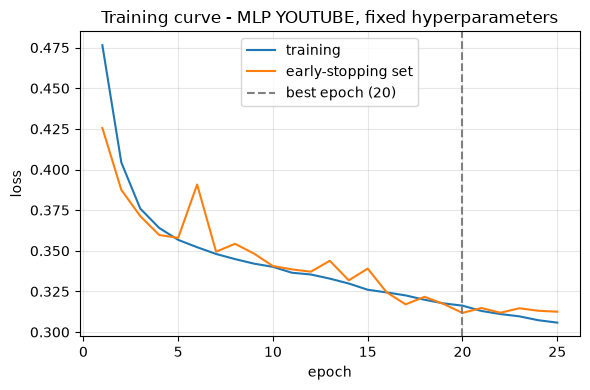

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
plot_training_curve(history["train_loss"], history["es_loss"], history["best_epoch"], ax=ax)
ax.set_title(f"Training curve - MLP {APP}, fixed hyperparameters")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(PLOTS_DIR / f"mlp_{APP.lower()}_training_curve_v0.png", dpi=150)
plt.show()

Metrics on the early-stopping set (optimistic, see above) just to check that the detector works: recall of class 1
well above 0, as Section 3 requires, and F1 above the share of positives (what a random guess would get).

In [6]:
y_pred_es = predict(model, X_es_s)
y_score_es = predict_proba(model, X_es_s)
metrics_es = compute_metrics(y_es, y_pred_es, y_score_es)
pd.Series(metrics_es, name="early-stopping set").round(3).to_frame()

,early-stopping set
accuracy,0.844
precision,0.723
recall,0.871
f1,0.790
auc_roc,0.937
pr_auc,0.889


We save weights, architecture and scaler in `results/models/` with `save_mlp`. Sections 3-4 load them with
`load_mlp("results/models/mlp_youtube")` (see `SECTION2_MLP_NOTES.md`). The scaler saved here is the one fitted on
the 90% used for training, so the model and its scaler are consistent. This file is overwritten in 2.3 with the model
trained with the best hyperparameters.

In [7]:
save_mlp(model, scaler, MODELS_DIR / f"mlp_{APP.lower()}")
sorted(p.name for p in MODELS_DIR.glob(f"mlp_{APP.lower()}*"))

['mlp_youtube.json', 'mlp_youtube.pt', 'mlp_youtube_scaler.joblib']